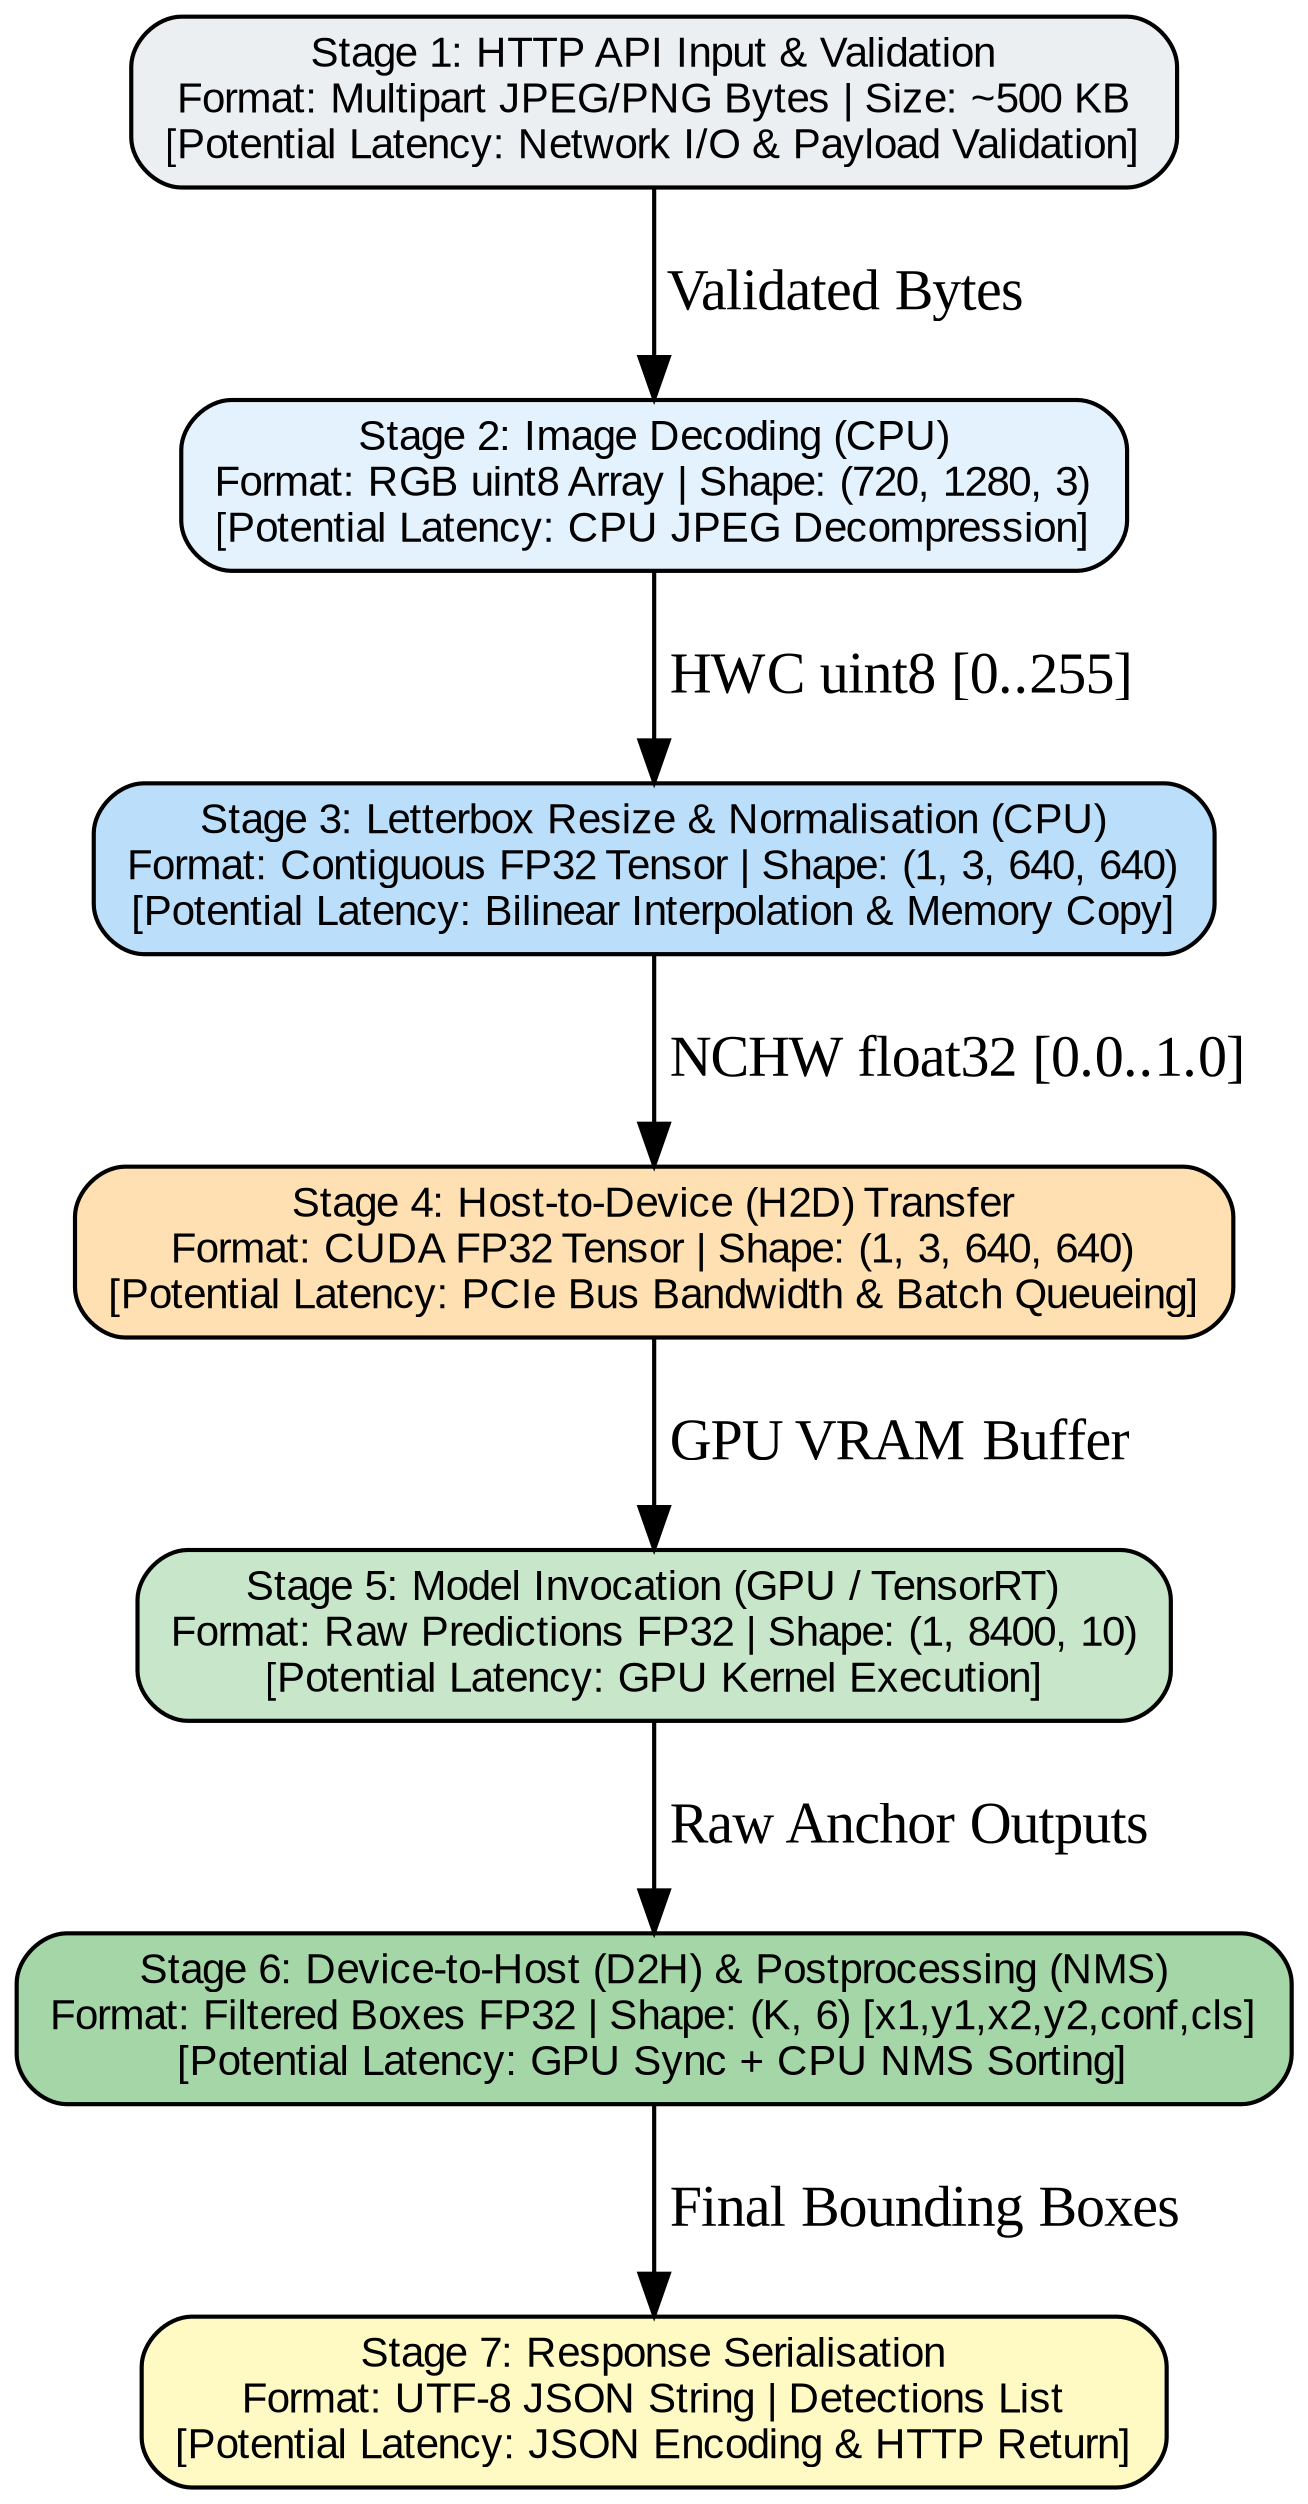


--- VisionPort End-to-End Request Trace (Device: cpu) ---
1. Request Validation   | Format: JPEG bytes     | Size: 552997 B        | Time: 33.91 ms
2. Image Decoding       | Format: uint8 ndarray | Shape: (720, 1280, 3)     | Time: 22.62 ms
3. Letterbox & Tensor   | Format: torch.float32  | Shape: (1, 3, 640, 640) | Time: 24.16 ms
4. H2D Transfer         | Format: cpu tensor    | Shape: (1, 3, 640, 640) | Time: 0.14 ms
5. Model Execution      | Format: torch.float32  | Shape: (1, 8400, 10)   | Time: 17.69 ms
6. D2H & NMS Postproc   | Format: torch.float32  | Shape: (1, 10)          | Time: 15.62 ms
7. JSON Serialisation   | Format: UTF-8 JSON str | Bytes: 119 B          | Time: 2.43 ms

Final API Output: {"detections": [{"class": "auto_rickshaw", "confidence": 0.91, "bbox_xyxy": [100.0, 120.0, 260.0, 300.0]}], "count": 1}


In [ ]:
import io
import time
import json
import numpy as np
import torch
import torchvision
from PIL import Image as PILImage
from graphviz import Digraph
from IPython.display import Image, display

# ==========================================
# PART 1: Generate Request Sequence Diagram
# ==========================================
dot = Digraph(comment='VisionPort Inference Request Sequence', format='png')
dot.attr(rankdir='TB', size='10,12', dpi='300', fontname='Helvetica')
dot.attr('node', shape='box', style='rounded,filled', fontname='Helvetica', fontsize='10')

dot.node('S1', 'Stage 1: HTTP API Input & Validation\nFormat: Multipart JPEG/PNG Bytes | Size: ~500 KB\n[Potential Latency: Network I/O & Payload Validation]', fillcolor='#ECEFF1')
dot.node('S2', 'Stage 2: Image Decoding (CPU)\nFormat: RGB uint8 Array | Shape: (720, 1280, 3)\n[Potential Latency: CPU JPEG Decompression]', fillcolor='#E3F2FD')
dot.node('S3', 'Stage 3: Letterbox Resize & Normalisation (CPU)\nFormat: Contiguous FP32 Tensor | Shape: (1, 3, 640, 640)\n[Potential Latency: Bilinear Interpolation & Memory Copy]', fillcolor='#BBDEFB')
dot.node('S4', 'Stage 4: Host-to-Device (H2D) Transfer\nFormat: CUDA FP32 Tensor | Shape: (1, 3, 640, 640)\n[Potential Latency: PCIe Bus Bandwidth & Batch Queueing]', fillcolor='#FFE0B2')
dot.node('S5', 'Stage 5: Model Invocation (GPU / TensorRT)\nFormat: Raw Predictions FP32 | Shape: (1, 8400, 10)\n[Potential Latency: GPU Kernel Execution]', fillcolor='#C8E6C9')
dot.node('S6', 'Stage 6: Device-to-Host (D2H) & Postprocessing (NMS)\nFormat: Filtered Boxes FP32 | Shape: (K, 6) [x1,y1,x2,y2,conf,cls]\n[Potential Latency: GPU Sync + CPU NMS Sorting]', fillcolor='#A5D6A7')
dot.node('S7', 'Stage 7: Response Serialisation\nFormat: UTF-8 JSON String | Detections List\n[Potential Latency: JSON Encoding & HTTP Return]', fillcolor='#FFF9C4')

dot.edge('S1', 'S2', label=' Validated Bytes')
dot.edge('S2', 'S3', label=' HWC uint8 [0..255]')
dot.edge('S3', 'S4', label=' NCHW float32 [0.0..1.0]')
dot.edge('S4', 'S5', label=' GPU VRAM Buffer')
dot.edge('S5', 'S6', label=' Raw Anchor Outputs')
dot.edge('S6', 'S7', label=' Final Bounding Boxes')

dot.render('visionport_sequence_diagram', cleanup=True)
display(Image('visionport_sequence_diagram.png'))

# ==========================================
# PART 2: Trace 1 Request & Record Shapes/Latency
# ==========================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n--- VisionPort End-to-End Request Trace (Device: {device}) ---")

# Stage 1: Simulate incoming HTTP JPEG payload
t0 = time.perf_counter()
raw_frame = PILImage.fromarray(np.random.randint(0, 255, (720, 1280, 3), dtype=np.uint8))
buf = io.BytesIO()
raw_frame.save(buf, format="JPEG")
http_bytes = buf.getvalue()
assert len(http_bytes) > 0, "Empty payload"
t1 = time.perf_counter()
print(f"1. Request Validation   | Format: JPEG bytes     | Size: {len(http_bytes)} B        | Time: {(t1-t0)*1000:.2f} ms")

# Stage 2: Image Decoding
img_pil = PILImage.open(io.BytesIO(http_bytes)).convert("RGB")
img_np = np.asarray(img_pil)
t2 = time.perf_counter()
print(f"2. Image Decoding       | Format: {img_np.dtype} ndarray | Shape: {img_np.shape}     | Time: {(t2-t1)*1000:.2f} ms")

# Stage 3: Letterbox Resize & Tensor Preparation (CPU)
scale = min(640 / img_np.shape[0], 640 / img_np.shape[1])
new_w, new_h = int(img_np.shape[1] * scale), int(img_np.shape[0] * scale)
resized = np.asarray(img_pil.resize((new_w, new_h), PILImage.BILINEAR))
canvas = np.full((640, 640, 3), 114, dtype=np.uint8)
pad_y, pad_x = (640 - new_h) // 2, (640 - new_w) // 2
canvas[pad_y:pad_y+new_h, pad_x:pad_x+new_w] = resized
cpu_tensor = torch.from_numpy(canvas).permute(2, 0, 1).unsqueeze(0).float().div_(255.0).contiguous()
t3 = time.perf_counter()
print(f"3. Letterbox & Tensor   | Format: {cpu_tensor.dtype}  | Shape: {tuple(cpu_tensor.shape)} | Time: {(t3-t2)*1000:.2f} ms")

# Stage 4: Host-to-Device (H2D) Transfer
if device.type == 'cuda':
    torch.cuda.synchronize()
t4_start = time.perf_counter()
gpu_tensor = cpu_tensor.to(device, non_blocking=True)
if device.type == 'cuda':
    torch.cuda.synchronize()
t4 = time.perf_counter()
print(f"4. H2D Transfer         | Format: {gpu_tensor.device} tensor    | Shape: {tuple(gpu_tensor.shape)} | Time: {(t4-t4_start)*1000:.2f} ms")

# Stage 5: Model Invocation (Simulated YOLO Backbone/Head forward pass)
model = torch.nn.Sequential(
    torch.nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1),
    torch.nn.SiLU(),
    torch.nn.AdaptiveAvgPool2d((1, 1)),
    torch.nn.Flatten(),
    torch.nn.Linear(16, 8400 * 10)
).to(device).eval()

with torch.inference_mode():
    _ = model(gpu_tensor)  # Warm-up
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t5_start = time.perf_counter()
    raw_preds = model(gpu_tensor).view(1, 8400, 10)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t5 = time.perf_counter()
print(f"5. Model Execution      | Format: {raw_preds.dtype}  | Shape: {tuple(raw_preds.shape)}   | Time: {(t5-t5_start)*1000:.2f} ms")

# Stage 6: D2H Transfer & Postprocessing (Confidence Filter + NMS)
preds_cpu = raw_preds.squeeze(0).cpu().clone()  # Avoid Inplace update to inference tensor error
# Inject 2 synthetic high-confidence traffic boxes for NMS demonstration
preds_cpu[0] = torch.tensor([100, 120, 260, 300, 0.91, 0.02, 0.94, 0.01, 0.01, 0.02])
preds_cpu[1] = torch.tensor([105, 125, 265, 305, 0.85, 0.02, 0.90, 0.01, 0.01, 0.06])
conf_mask = preds_cpu[:, 4] > 0.5
filtered = preds_cpu[conf_mask]
keep = torchvision.ops.nms(filtered[:, :4], filtered[:, 4], iou_threshold=0.45)
final_boxes = filtered[keep]
t6 = time.perf_counter()
print(f"6. D2H & NMS Postproc   | Format: {final_boxes.dtype}  | Shape: {tuple(final_boxes.shape)}          | Time: {(t6-t5)*1000:.2f} ms")

# Stage 7: JSON Response Serialisation
CLASSES = ["car", "auto_rickshaw", "two_wheeler", "bus", "truck"]
detections = [
    {"class": CLASSES[int(torch.argmax(b[5:]))], "confidence": round(float(b[4]), 3), "bbox_xyxy": [round(float(x), 1) for x in b[:4]]}
    for b in final_boxes
]
json_response = json.dumps({"detections": detections, "count": len(detections)})
t7 = time.perf_counter()
print(f"7. JSON Serialisation   | Format: UTF-8 JSON str | Bytes: {len(json_response)} B          | Time: {(t7-t6)*1000:.2f} ms")
print(f"\nFinal API Output: {json_response}")